In [153]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from IPython.display import display

### **METODE RELAKSASI / SOR**

In [154]:
def SOR(A, b, omega, epsilon=0.1, max_iter=100):
    n = len(A)
    x = np.zeros(n) #Tebakan awal 0
    history = [x.copy()]
    iterasi = 1

    while iterasi <= max_iter:
        x_old = x.copy()

        for i in range(n):
            jumlah = 0
            for j in range(n):
                if j < i:
                    jumlah += A[i][j] * x[j]    
                elif j > i:
                    jumlah += A[i][j] * x_old[j] 
            
            x_gs = (b[i] - jumlah) / A[i][i]
            x[i] = (1 - omega) * x_old[i] + omega * x_gs

        history.append(x.copy())

        err = max(abs(x[i] - x_old[i]) for i in range(n))
        if err < epsilon:
            return x, history, iterasi

        iterasi += 1

    print("MENCAPAI BATAS ITERASI - 100")
    return x, history, iterasi+1


### **METODE CONJUGASI GRADIEN**

In [155]:
def bicgstab(A, b, epsilon=0.1, max_iter=100):
    # Konversi ke numpy array (biar operasi linear algebra bisa dipakai)
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    
    # Inisialisasi solusi awal (x0 = 0)
    x = np.zeros(n)
    
    # Menyimpan riwayat solusi untuk keperluan grafik
    history = [x.copy()]
    
    # Residual awal: r0 = b - A x0
    r = b - A @ x
    
    # r_hat adalah "vektor bayangan"
    # biasanya diambil sama dengan residual awal
    r_hat = r.copy()
    
    # Inisialisasi parameter BiCGSTAB
    rho_prev = 1.0   # skalar untuk update arah
    alpha = 1.0      # langkah utama (mirip CG)
    omega = 1.0      # langkah stabilisasi
    
    v = np.zeros(n)  # vektor bantu
    p = np.zeros(n)  # arah pencarian (search direction)

    # Loop iterasi utama
    for iterasi in range(max_iter):
        
        
        # 1. Hitung rho (inner product)
        rho = np.dot(r_hat, r)
        
        # Jika rho = 0 → metode gagal (vektor ortogonal)
        if rho == 0:
            print("Gagal: rho = 0 (breakdown)")
            break
        
        
        # 2. Update arah pencarian p
        beta = (rho / rho_prev) * (alpha / omega)
        
        # Kombinasi arah sebelumnya + koreksi
        p = r + beta * (p - omega * v)
        
        
        # 3. Hitung v = A p
        v = A @ p
        
        denom = np.dot(r_hat, v)
        if denom == 0:
            print("Gagal: pembagian nol pada alpha")
            break
        
        
        # 4. Langkah agresif (seperti CG)
        alpha = rho / denom
        
        # Residual sementara
        s = r - alpha * v
        
        
        # 5. Langkah stabilisasi
        t = A @ s
        
        t_dot_t = np.dot(t, t)
        if t_dot_t == 0:
            print("Gagal: t_dot_t = 0")
            break
        
        # Hitung omega untuk "menstabilkan"
        omega = np.dot(t, s) / t_dot_t
        
        
        # 6. Update solusi x
        # Gabungan:
        # - langkah agresif (alpha * p)
        # - langkah stabilisasi (omega * s)
        x = x + alpha * p + omega * s
        
        
        # 7. Update residual baru 
        r = s - omega * t
        
        # Simpan riwayat solusi
        history.append(x.copy())
        
        
        # 8. Cek konvergensi
        # Menggunakan residual (lebih sesuai untuk BiCGSTAB)
        error = np.linalg.norm(r) / np.linalg.norm(b)
        
        if error < epsilon:
            return x, history, iterasi + 1
        
        # Simpan rho untuk iterasi berikutnya
        rho_prev = rho

    print("Mencapai batas iterasi maksimum")
    return x, history, len(history)


### **OUTPUT + GRAFIK**

In [156]:
def output_sor(kasus, omega):
    A, b = kasus
    tabel_data = []


    solusi, history, iterasi = SOR(A, b, omega)
        
    # Looping setiap iterasi pada nilai Omega tersebut
    for i in range(len(history)):
        x1_val = history[i][0]
        x2_val = history[i][1]
        
        # Hitung error (iterasi ke-0 belum punya error)
        if i == 0:
            error_x1 = history[i][i]
            error_x2 = history[i][i]
        else:
            # [[a , b] ,[c , d]] --> c - a , d - b 
            error_x1 = abs(history[i][0] - history[i-1][0]) 
            error_x2 =  abs(history[i][1] - history[i-1][1])
            
        # Memasukkan baris data ke dalam list
        tabel_data.append({
            "Omega": omega,
            "Iterasi": i,
            "x1": x1_val,
            "x2": x2_val,
            "Error x1": error_x1,
            "Error x2": error_x2
        })

    # Mengubah list data menjadi tabel Pandas DataFrame
    df = pd.DataFrame(tabel_data)
    
    # Menampilkan tabel dengan rapi di Jupyter Notebook
    display(df)

In [157]:
def output_bicgstab(kasus):
    A, b = kasus
    tabel_data = []

    solusi, history, iterasi = bicgstab(A, b)
        
    # Looping setiap iterasi pada nilai Omega tersebut
    for i in range(len(history)):
        x1_val = history[i][0]
        x2_val = history[i][1]
        
        # Hitung error (iterasi ke-0 belum punya error)
        if i == 0:
            error_x1 = history[i][i]
            error_x2 = history[i][i]
        else:
            # [[a , b] ,[c , d]] --> c - a , d - b 
            error_x1 = abs(history[i][0] - history[i-1][0]) 
            error_x2 =  abs(history[i][1] - history[i-1][1])
            
        # Memasukkan baris data ke dalam list
        tabel_data.append({
            "Metode": "BiConjugate Gradient Stabilized",
            "Iterasi": i,
            "x1": x1_val,
            "x2": x2_val,
            "Error x1": error_x1,
            "Error x2": error_x2
        })

    # Mengubah list data menjadi tabel Pandas DataFrame
    df = pd.DataFrame(tabel_data)
    
    # Menampilkan tabel dengan rapi di Jupyter Notebook
    display(df)

# **KASUS**

## 📌 Kasus Produksi Dua Mesin dalam Sistem Industri

Kasus ini memodelkan proses produksi pada sebuah pabrik yang menggunakan **dua mesin utama** untuk menghasilkan dua jenis produk secara paralel.

* **Mesin A**
* **Mesin B**

Kedua mesin memiliki kontribusi produksi yang berbeda pada masing-masing produk.

---

## 🔹 Karakteristik Produksi

### ⚙️ Produk 1

* Produksi didominasi oleh **Mesin A**
* Rasio kontribusi: **8 : 1** (A : B)
* Total produksi: **36 unit**

---

### 🏭 Produk 2

* Produksi didominasi oleh **Mesin B**
* Rasio kontribusi: **1 : 5** (A : B)
* Total produksi: **30 unit**

---

## 🔹 Pemodelan Sistem Persamaan Linear (SPL)

Misalkan:

* $x_1$ = kapasitas produksi **Mesin A**
* $x_2$ = kapasitas produksi **Mesin B**

Berdasarkan informasi yang diberikan, diperoleh sistem persamaan:

$$
\begin{cases}
8x_1 + x_2 = 36 \\
x_1 + 5x_2 = 30
\end{cases}
$$

---

## 🔹 Interpretasi Matriks

Sistem di atas dapat dituliskan dalam bentuk matriks sebagai berikut:

$$
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
\begin{bmatrix}
x_1 \\
x_2
\end{bmatrix}
=

\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

---

## 🔹 Representasi Matriks

$$
A =
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
\quad
b =
\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

---

## 🔹 Tujuan

Menentukan nilai:

* $x_1$ → kapasitas produksi Mesin A
* $x_2$ → kapasitas produksi Mesin B

agar sistem produksi memenuhi target kedua produk secara optimal.

---


In [158]:
#Matriks A
A = np.array([
    [8, 1],
    [1, 5]
], dtype=float)

#Matriks b
b = np.array([36, 30], dtype=float)

kasus1 = (A,b)

## **TABEL SOR**

In [159]:
# Tabel
x, history, iterasi = SOR(A, b, 1)
omega_list = [0.5 ,1.0, 1.5]
for o in omega_list:
    output_sor(kasus1, o)

,Omega,Iterasi,x1,x2,Error x1,Error x2
0,0.5,0,0.000000,0.000000,0.000000,0.000000
1,0.5,1,2.250000,2.775000,2.250000,2.775000
2,0.5,2,3.201563,4.067344,0.951563,1.292344
3,0.5,3,3.596572,4.674015,0.395010,0.606671
4,0.5,4,3.756160,4.961391,0.159588,0.287377
5,0.5,5,3.817993,5.098896,0.061833,0.137505
6,0.5,6,3.840316,5.165417,0.022322,0.066520


,Omega,Iterasi,x1,x2,Error x1,Error x2
0,1.0,0,0.000000,0.000000,0.000000,0.000000
1,1.0,1,4.500000,5.100000,4.500000,5.100000
2,1.0,2,3.862500,5.227500,0.637500,0.127500
3,1.0,3,3.846563,5.230688,0.015937,0.003188


,Omega,Iterasi,x1,x2,Error x1,Error x2
0,1.5,0,0.000000,0.000000,0.000000,0.000000
1,1.5,1,6.750000,6.975000,6.750000,6.975000
2,1.5,2,2.067187,4.892344,4.682813,2.082656
3,1.5,3,4.799092,5.114101,2.731904,0.221757
4,1.5,4,3.391560,5.425482,1.407532,0.311381
5,1.5,5,4.036942,5.076177,0.645382,0.349305
6,1.5,6,3.779746,5.327988,0.257196,0.251811
7,1.5,7,3.861129,5.177667,0.081383,0.150321
8,1.5,8,3.848623,5.256580,0.012507,0.078912


## **GRAFIK SOR**

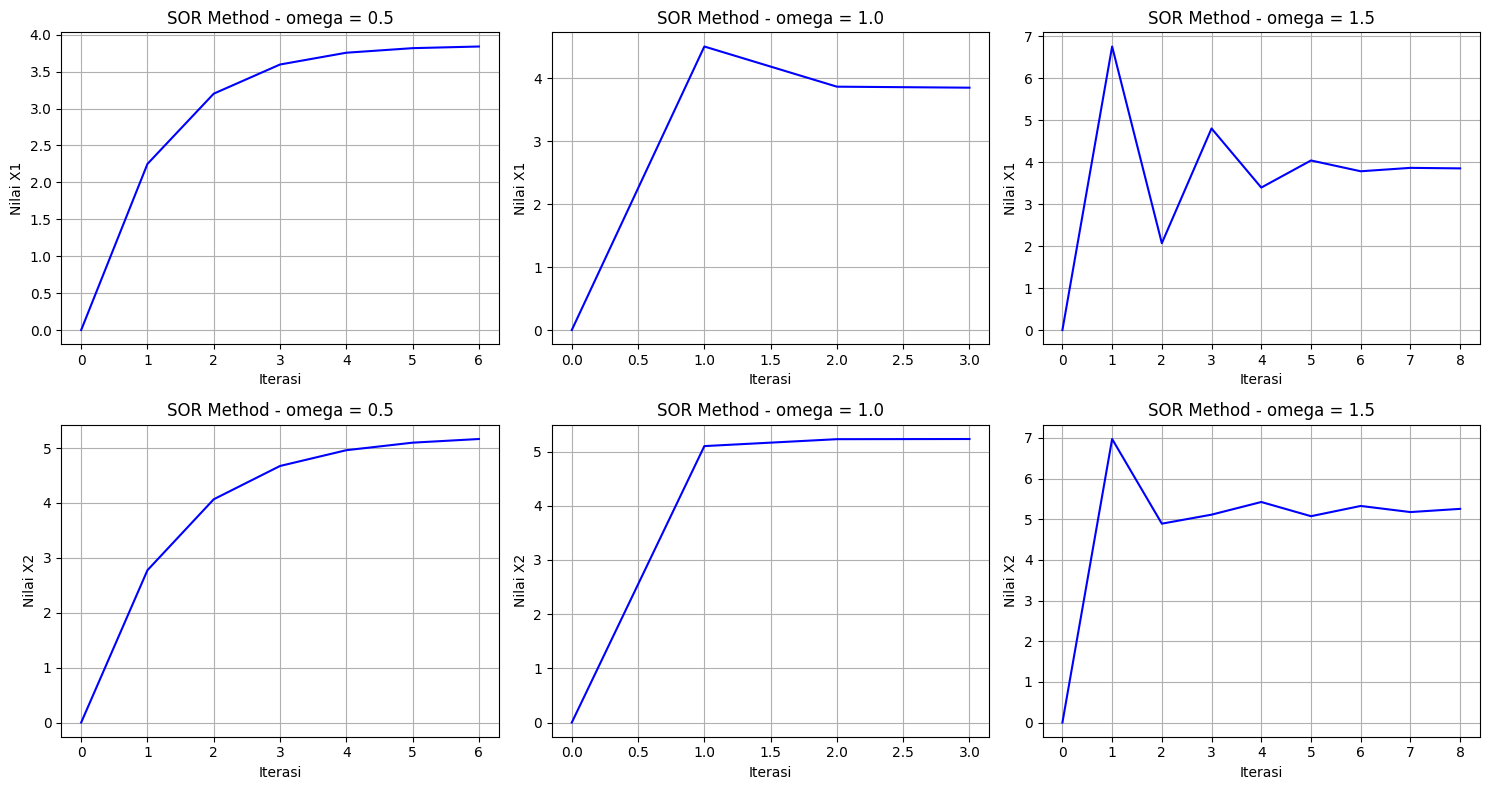

In [160]:
# Grafik
omega_list = [0.5 ,1.0, 1.5]

#Membuat template 2 baris 3 kolom
fig, axs = plt.subplots (2, len(omega_list), figsize = (15, 8))

for n in range(len(omega_list)):
    x, history, iterasi = SOR(A, b, omega_list[n])
    
    for baris in range(2):
        #Kolom n
        axs[baris][n].plot(range(len(history)), #sumbu x
                    [h[baris] for h in history], #sumbu y
                    color='blue')
        axs[baris][n].set_title(f'SOR Method - omega = {omega_list[n]}')
        axs[baris][n].set_xlabel('Iterasi')
        axs[baris][n].set_ylabel(f'Nilai X{baris+1}')
        axs[baris][n].grid(True)
        
        # Agar antar grafik tidak saling bertabrakan (merapikan tata letak)
plt.tight_layout()

        # Tampilkan
plt.show()

## **TABEL BiCGSTAB**

In [161]:
# Tabel
x, history, iterasi = bicgstab(A, b)
output_bicgstab(kasus1)

,Metode,Iterasi,x1,x2,Error x1,Error x2
0,BiConjugate Gradient Stabilized,0,0.000000,0.000000,0.000000,0.000000
1,BiConjugate Gradient Stabilized,1,3.742435,4.949247,3.742435,4.949247


## **GRAFIK BiCGSTAB**

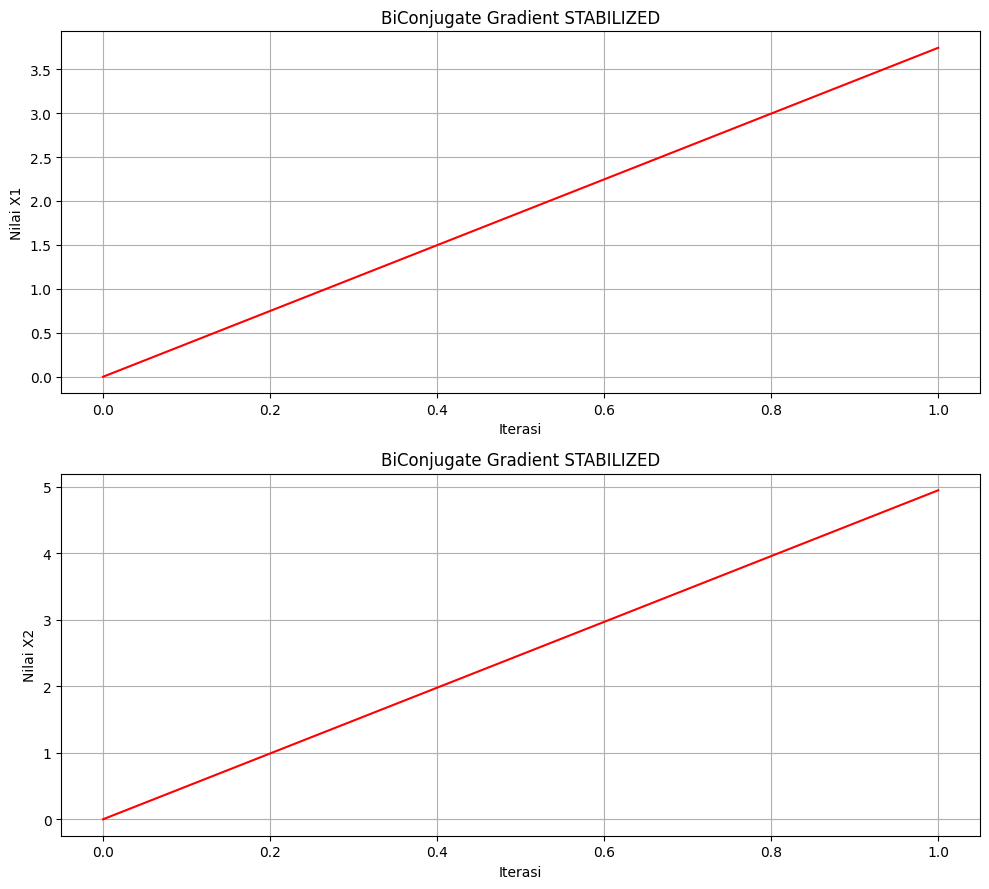

In [162]:
# Grafik

#Membuat template 2 baris 1
fig, axs = plt.subplots (2, 1, figsize = (10, 9))


x, history, iterasi = bicgstab(A, b)
    
for baris in range(2):
    #Kolom n
    axs[baris].plot(range(len(history)), #sumbu x
                [h[baris] for h in history], #sumbu y
                color='red')
    axs[baris].set_title(f'BiConjugate Gradient STABILIZED')
    axs[baris].set_xlabel('Iterasi')
    axs[baris].set_ylabel(f'Nilai X{baris+1}')
    axs[baris].grid(True)
    
    # Agar antar grafik tidak saling bertabrakan (merapikan tata letak)
plt.tight_layout()

        # Tampilkan
plt.show()

## **GRAFIK PERBANDINGAN**

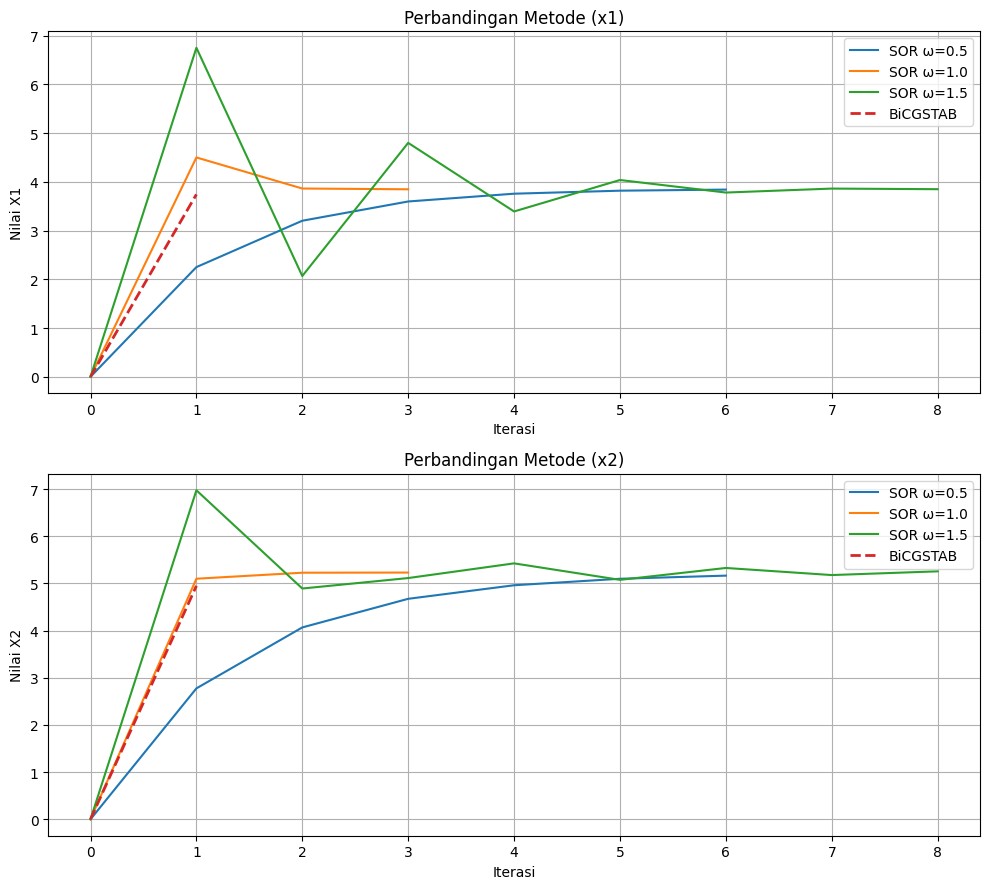

In [163]:
omega_list = [0.5, 1.0, 1.5]

fig, axs = plt.subplots(2, 1, figsize=(10, 9))


# Plot SOR dulu

for n in range(len(omega_list)):
    x_sor, history_sor, _ = SOR(A, b, omega_list[n])
    
    for baris in range(2):
        axs[baris].plot(
            range(len(history_sor)),
            [h[baris] for h in history_sor],
            label=f'SOR ω={omega_list[n]}'
        )


# Plot BiCGSTAB

x_bicg, history_bicg, _ = bicgstab(A, b)

for baris in range(2):
    axs[baris].plot(
        range(len(history_bicg)),
        [h[baris] for h in history_bicg],
        linestyle='--',  # beda style biar kelihatan
        linewidth=2,
        label='BiCGSTAB'
    )


# Styling

for baris in range(2):
    axs[baris].set_title(f'Perbandingan Metode (x{baris+1})')
    axs[baris].set_xlabel('Iterasi')
    axs[baris].set_ylabel(f'Nilai X{baris+1}')
    axs[baris].grid(True)
    axs[baris].legend()   # 

plt.tight_layout()
